In [51]:
import pandas as pd
import numpy as np
import os
import sys
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization
import matplotlib.gridspec as gridspec
from scipy import stats
from tqdm import tqdm

In [12]:
pip install openpyxl



   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]




[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
df=pd.read_excel(r'S:\Codes\Practice_Scripts\Fraud_Detection_M_ProjectL\dataset\online+retail+ii\online_retail_II.xlsx') #low_memory=False is used to avoid dtype warning for large datasets. It will use more memory but will be faster.

In [70]:
file_path = r'S:\Codes\Practice_Scripts\Fraud_Detection_M_ProjectL\dataset\online+retail+ii\online_retail_II.xlsx'

# sheet_name=None loads all sheets as a dictionary of DataFrames
sheets_dict = pd.read_excel(file_path, sheet_name=None)

# Combine all sheets into one DataFrame
df = pd.concat(sheets_dict.values(), ignore_index=True)

# Verify the sheet names and combined shape
print("Loaded sheets:", list(sheets_dict.keys()))
print("Combined shape:", df.shape)

Loaded sheets: ['Year 2009-2010', 'Year 2010-2011']
Combined shape: (1067371, 8)


In [71]:
df.shape

(1067371, 8)

In [72]:
df.head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [73]:
df.sample(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179435,506408,82482,WOODEN PICTURE FRAME WHITE FINISH,6,2010-04-29 13:50:00,2.55,15768.0,United Kingdom
437175,531210,48185,DOORMAT FAIRY CAKE,1,2010-11-05 16:07:00,7.95,13263.0,United Kingdom
633914,545534,20725,LUNCH BAG RED RETROSPOT,10,2011-03-03 14:05:00,1.65,17652.0,United Kingdom
542942,537764,22569,FELTCRAFT CUSHION BUTTERFLY,1,2010-12-08 12:06:00,3.75,16893.0,United Kingdom
65749,495239,22134,LADLE LOVE HEART RED,1,2010-01-22 10:01:00,0.85,NaN,United Kingdom
53141,494239,21624,VINTAGE UNION JACK DOORSTOP,1,2010-01-12 15:48:00,5.95,14081.0,United Kingdom
316770,520214,20914,SET/5 RED SPOTTY LID GLASS BOWLS,32,2010-08-25 07:46:00,2.55,14895.0,United Kingdom
552252,538524,20668,DISCO BALL CHRISTMAS DECORATION,6,2010-12-13 09:35:00,0.43,NaN,United Kingdom
771335,558637,22804,CANDLEHOLDER PINK HANGING HEART,1,2011-06-30 20:08:00,2.95,17891.0,United Kingdom
216625,510428,82600,NO SINGING METAL SIGN,12,2010-05-30 12:48:00,2.10,17617.0,United Kingdom


In [74]:
df.describe(include='all')  

'''
we can check the statiscal summary of the dataset 
we can also check outliers from here just by looking at the min and max values of each column, if there is huge diffrence beteween them then they might be have outliers , 
similarly for 75% and max values then there are chances of outliers present in the datset
'''

'\nwe can check the statiscal summary of the dataset \nwe can also check outliers from here just by looking at the min and max values of each column, if there is huge diffrence beteween them then they might be have outliers , \nsimilarly for 75% and max values then there are chances of outliers present in the datset\n'

In [75]:
df.describe(include='all')  

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,1067371.0,1067371,1062989,1.067371e+06,1067371,1.067371e+06,824364.000000,1067371
unique,53628.0,5305,5698,NaN,NaN,NaN,NaN,43
top,537434.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1350.0,5829,5918,NaN,NaN,NaN,NaN,981330
mean,NaN,NaN,NaN,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504,NaN
min,NaN,NaN,NaN,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000,NaN
50%,NaN,NaN,NaN,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000,NaN
75%,NaN,NaN,NaN,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000,NaN
max,NaN,NaN,NaN,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000,NaN


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [77]:
''' 
as lots of columns are Object dtype : so we can convert all them into string type because these columns has mixed data types like number , numberic+letters , lettters etc. 
so here we are making all of them into single stringtype

Creating new columns from existing columns like Invoice_str has two types of data : cancelled and non cancelled invoces so we can create a new column is_cancelled which will have 1 for cancelled invoices and 0 for non cancelled invoices

'''

# 1. Standardize object columns to string before string operations
df['Invoice_str'] = df['Invoice'].astype(str).str.strip()
df['StockCode_str'] = df['StockCode'].astype(str).str.strip()

# 2. Extract cancellation flag from Invoice ('C' prefix)
df['is_cancelled'] = df['Invoice_str'].str.startswith('C').astype(int)

# 3. Audit non-standard StockCodes (codes that don't start with digits)
non_product_mask = ~df['StockCode_str'].str[0].str.isdigit()
print("Non-product StockCodes:", df.loc[non_product_mask, 'StockCode_str'].value_counts().head(15))

# 4. Inspect Country distribution to plan rare-category grouping
print("\nTop Countries (%):\n", (df['Country'].value_counts(normalize=True) * 100).head(10))

Non-product StockCodes: StockCode_str
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
Name: count, dtype: int64

Top Countries (%):
 Country
United Kingdom    91.938979
EIRE               1.673832
Germany            1.651160
France             1.342551
Netherlands        0.481557
Spain              0.357045
Switzerland        0.298771
Belgium            0.292588
Portugal           0.245463
Australia          0.179225
Name: proportion, dtype: float64


In [78]:
df.describe(include='all')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Invoice_str,StockCode_str,is_cancelled
count,1067371.0,1067371,1062989,1.067371e+06,1067371,1.067371e+06,824364.000000,1067371,1067371,1067371,1.067371e+06
unique,53628.0,5305,5698,NaN,NaN,NaN,NaN,43,53628,5304,NaN
top,537434.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom,537434,85123A,NaN
freq,1350.0,5829,5918,NaN,NaN,NaN,NaN,981330,1350,5829,NaN
mean,NaN,NaN,NaN,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504,NaN,NaN,NaN,1.826357e-02
min,NaN,NaN,NaN,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000,NaN,NaN,NaN,0.000000e+00
25%,NaN,NaN,NaN,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000,NaN,NaN,NaN,0.000000e+00
50%,NaN,NaN,NaN,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000,NaN,NaN,NaN,0.000000e+00
75%,NaN,NaN,NaN,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000,NaN,NaN,NaN,0.000000e+00
max,NaN,NaN,NaN,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000,NaN,NaN,NaN,1.000000e+00


In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 11 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Invoice        1067371 non-null  object        
 1   StockCode      1067371 non-null  object        
 2   Description    1062989 non-null  object        
 3   Quantity       1067371 non-null  int64         
 4   InvoiceDate    1067371 non-null  datetime64[ns]
 5   Price          1067371 non-null  float64       
 6   Customer ID    824364 non-null   float64       
 7   Country        1067371 non-null  object        
 8   Invoice_str    1067371 non-null  object        
 9   StockCode_str  1067371 non-null  object        
 10  is_cancelled   1067371 non-null  int32         
dtypes: datetime64[ns](1), float64(2), int32(1), int64(1), object(6)
memory usage: 85.5+ MB


In [80]:
'''
so here we have 2 columns  with null values, Description: 2928 and customer id: 107927

total shape of the dataset is : (525461, 8)

So we can drop the rows with null values in customer id column as it is very important for our analysis and we can fill the null values in description column with 'No Description' or 'Unknown' as it is not that important for our analysis.

'''

df.isnull().sum()



Invoice               0
StockCode             0
Description        4382
Quantity              0
InvoiceDate           0
Price                 0
Customer ID      243007
Country               0
Invoice_str           0
StockCode_str         0
is_cancelled          0
dtype: int64

In [81]:
''' 
there are 6865 duplicated rows in the datset, we can drop this rows as it is not useful for our analysis.
'''

df.duplicated().sum()



34335

In [ ]:
##EDA

In [82]:
# Identifying numerical and categorical columns
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

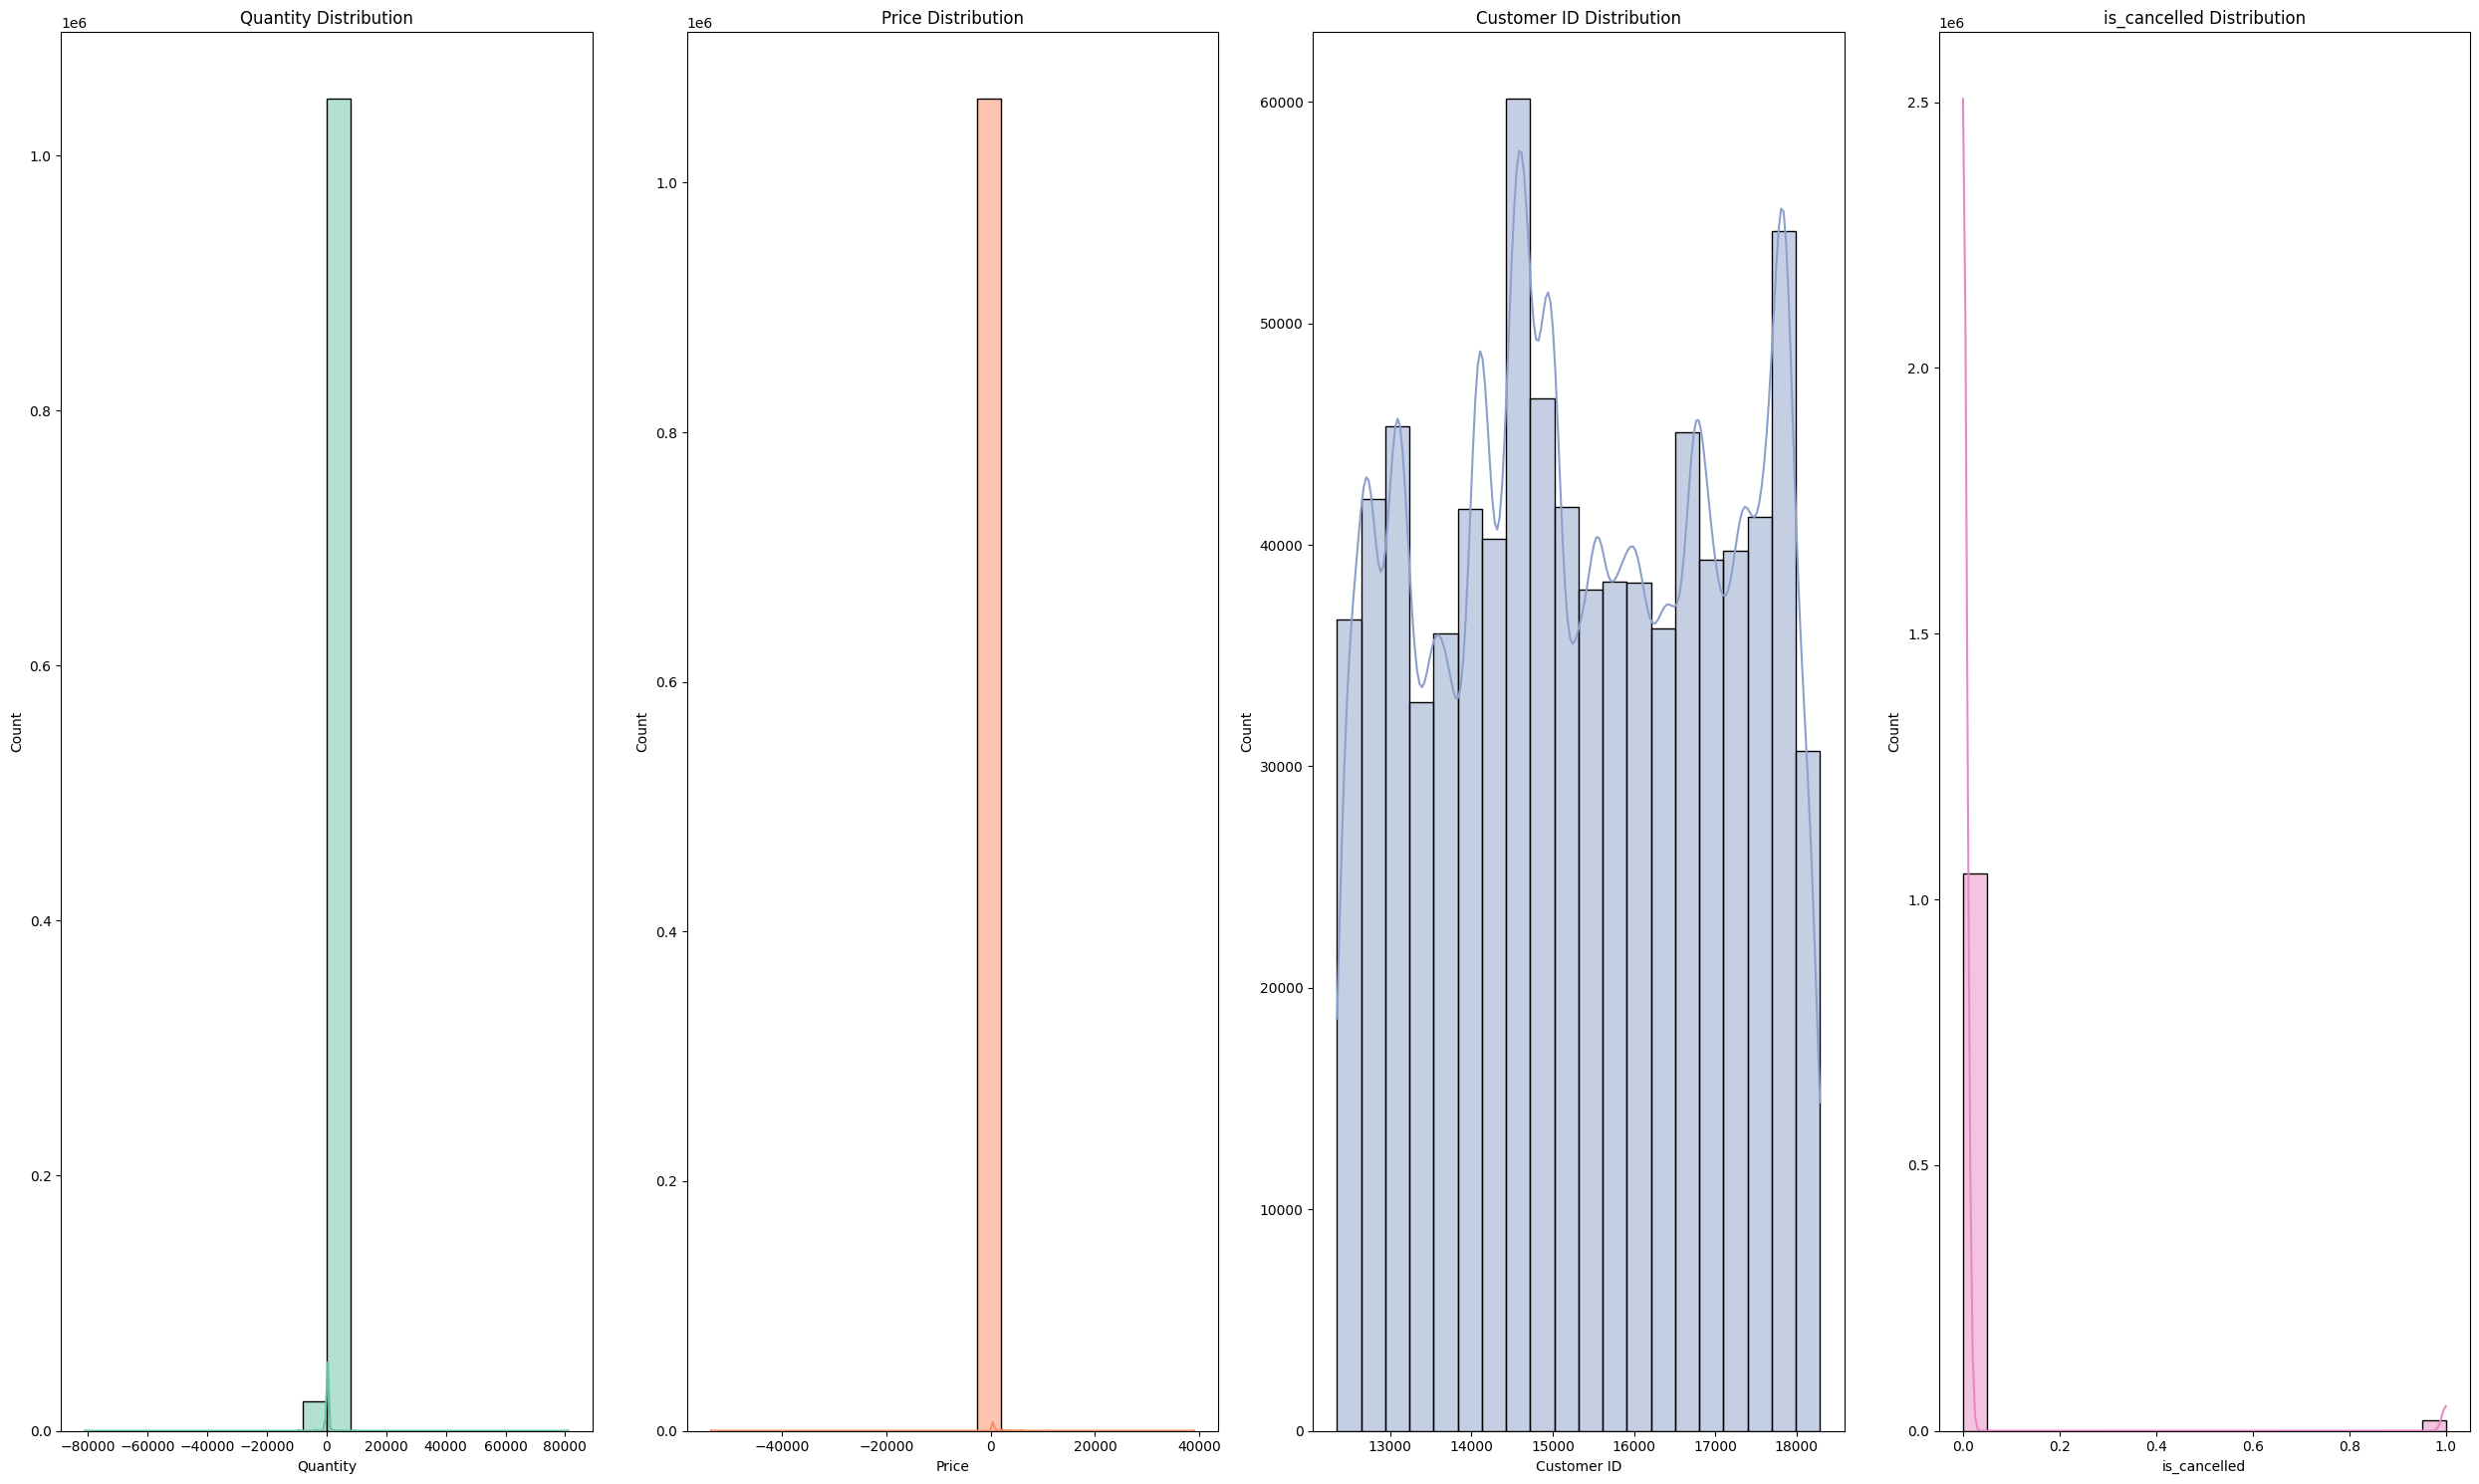

In [83]:
#Histograms for numerical columns
plt.figure(figsize=(25, 15))
for i, col in enumerate(numerical_cols):
    plt.subplot(int(np.ceil(len(numerical_cols)/4)), 4, i+1)
    sns.histplot(df[col], kde=True, bins=20, color=sns.color_palette("Set2")[i % 8])
    plt.title(f"{col} Distribution")
plt.tight_layout()
plt.show()

in above histogram we analysis that is_cancleed part is imbalanced data

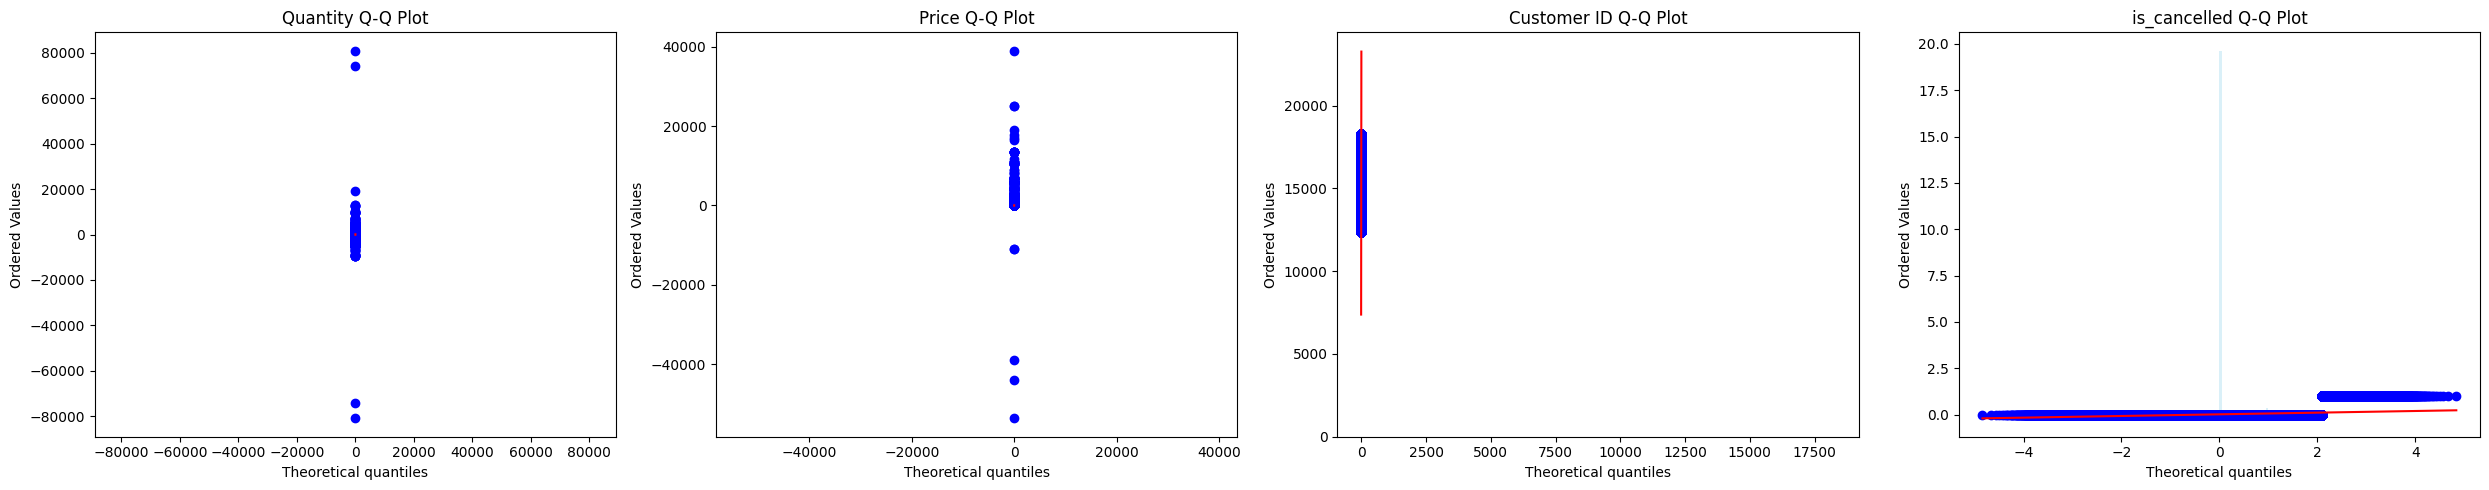

In [84]:
#Q-Q Plots with Histogram Overlay
'''   
Most variables have approximately normal distributions after removing leaks, 
with moderate skewness. 
Tails reveal outliers that may require special attention in modeling. Discrete indices show concentration in middle categories, consistent with overall moderate population trends.
'''
n_cols = 4
n_rows = int(np.ceil(len(numerical_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(25, 5*n_rows))
axes = axes.flatten()
for idx, col in enumerate(numerical_cols):
    stats.probplot(df[col].dropna(), dist="norm", plot=axes[idx])
    axes[idx].set_title(f"{col} Q-Q Plot")
    axes[idx].hist(df[col].dropna(), bins=20, alpha=0.3, color='skyblue', density=True)
# Remove empty axes
for j in range(idx+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

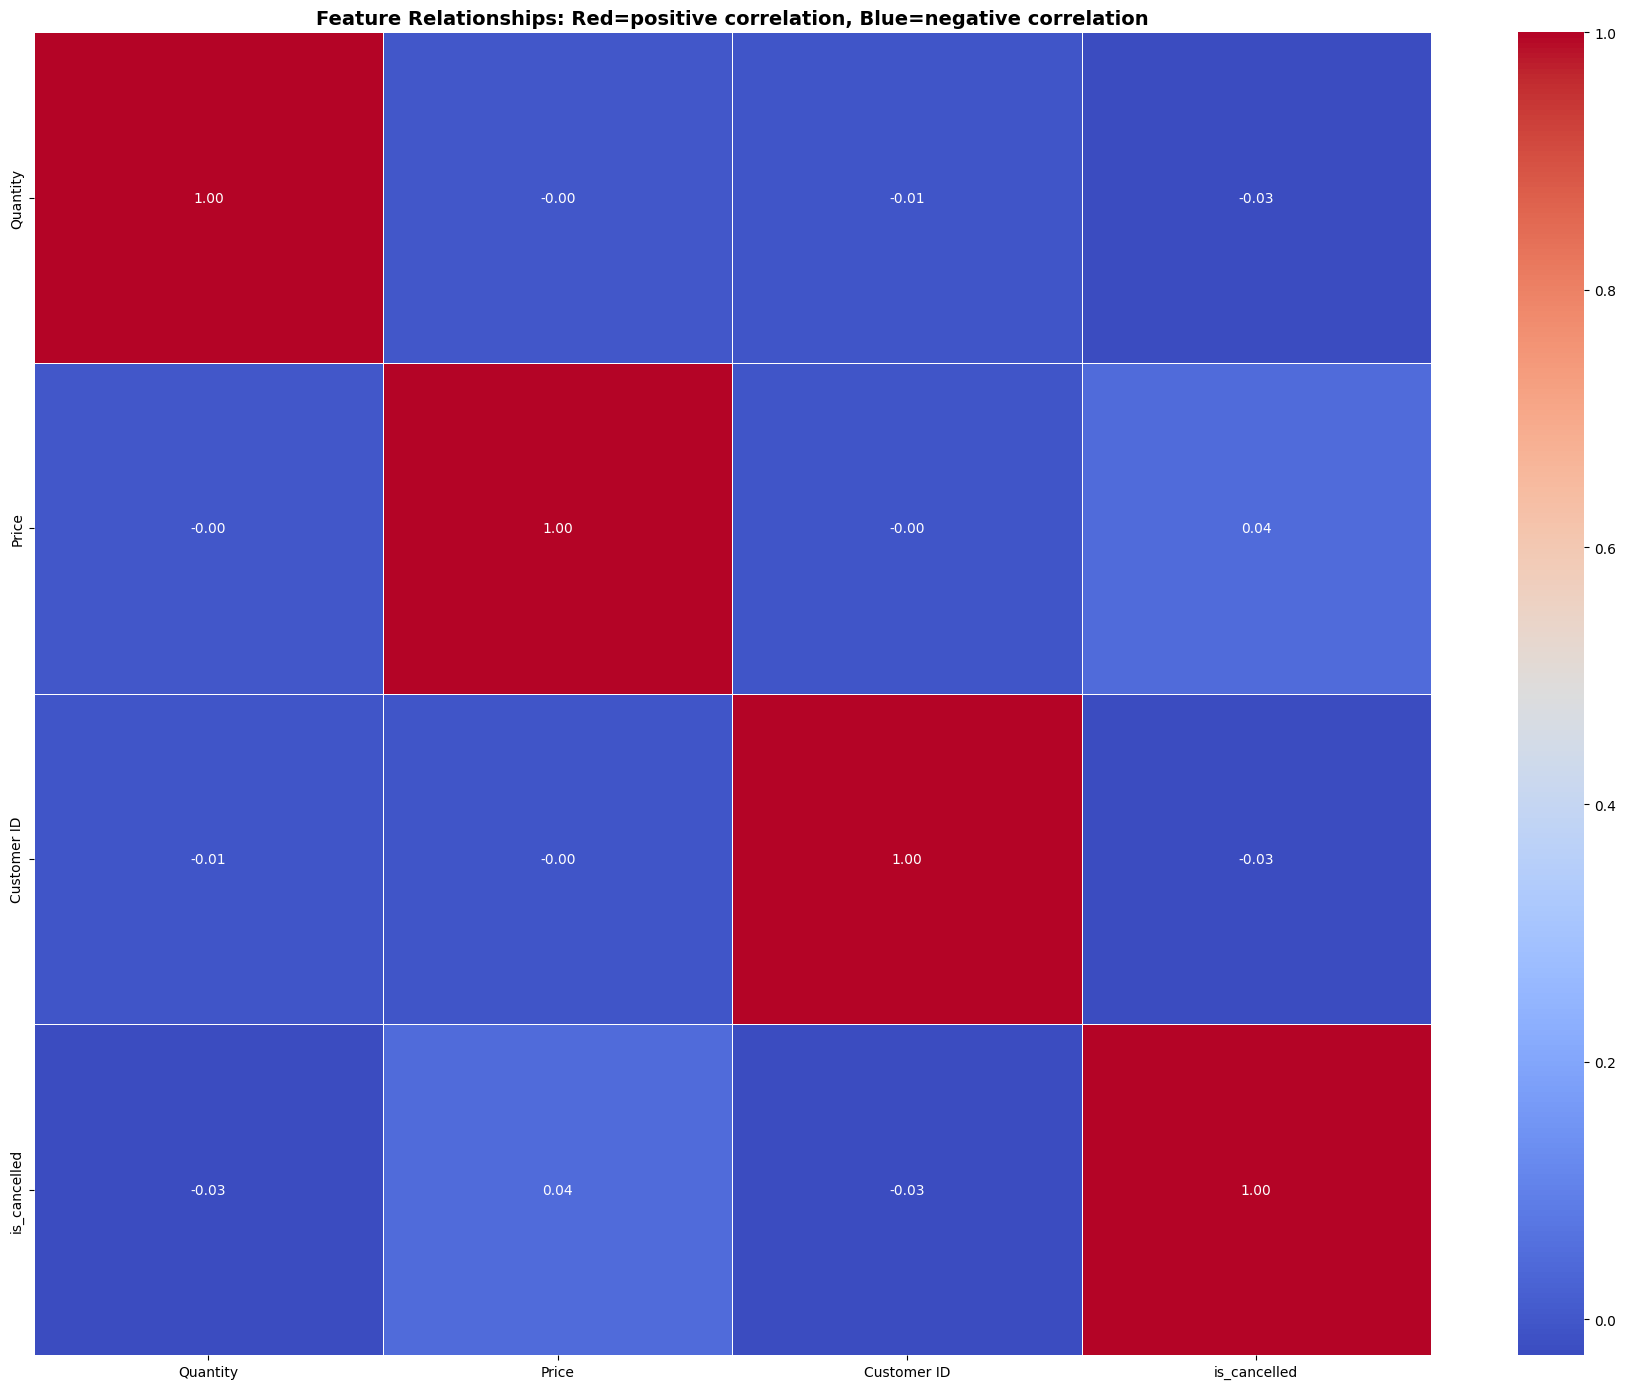

In [85]:
# Correlation Heatmap

'''   
The three deprivation indices (in the below right corner of heat map) have perfect correlations (r = 0.91-1.00) with each other.
Whether we can  measure educational deprivation relatively, absolutely, or categorically we will get the same result. 
This validates the data's integrity.
Therefore we will later drop two of these three columns to avoid redundancy in modeling.
'''
plt.figure(figsize=(18, 14))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title("Feature Relationships: Red=positive correlation, Blue=negative correlation", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

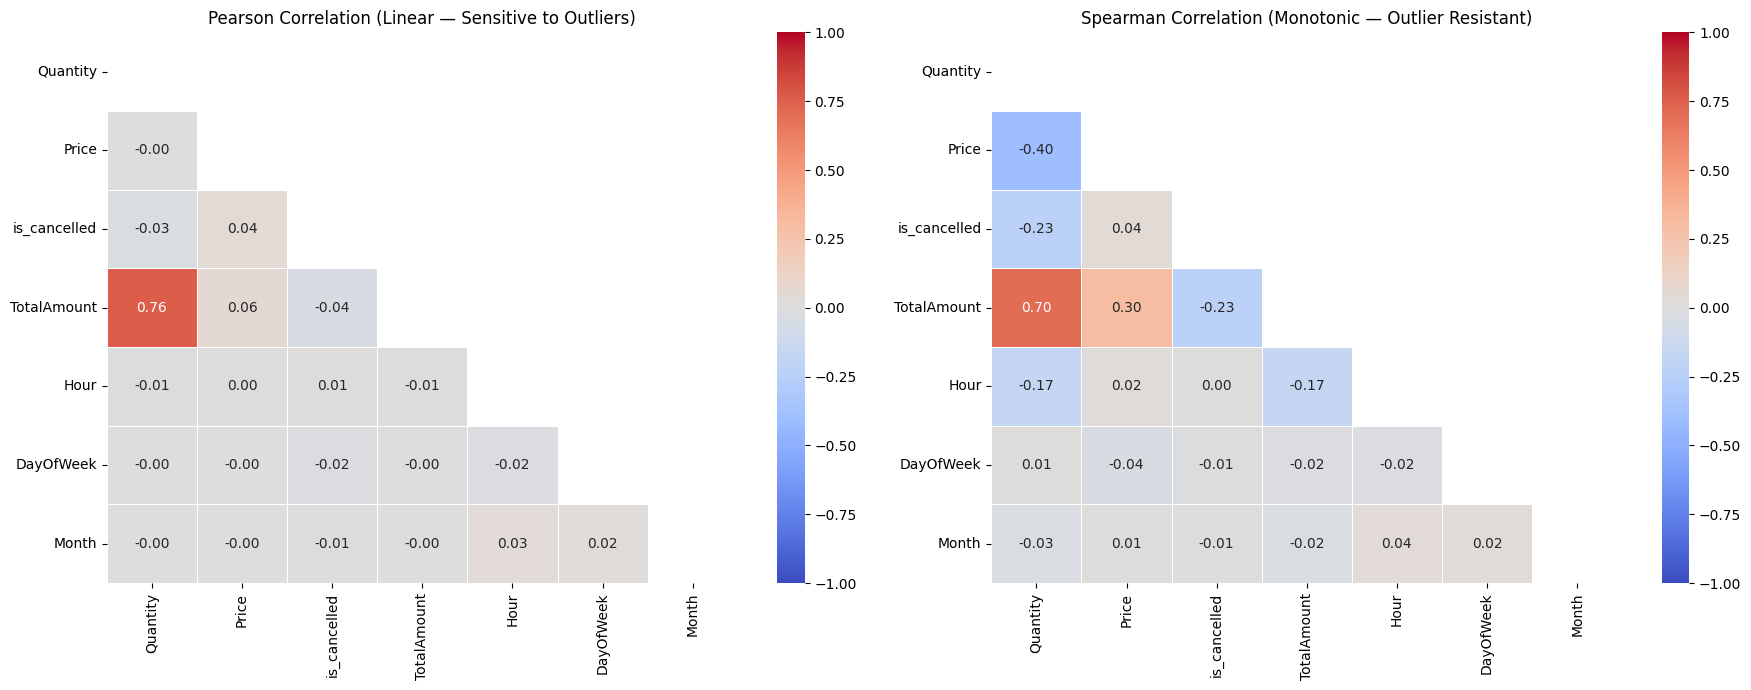

In [86]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create temporary numeric features for correlation exploration
corr_df = df[['Quantity', 'Price', 'is_cancelled']].copy()
corr_df['TotalAmount'] = df['Quantity'] * df['Price']
corr_df['Hour'] = df['InvoiceDate'].dt.hour
corr_df['DayOfWeek'] = df['InvoiceDate'].dt.dayofweek
corr_df['Month'] = df['InvoiceDate'].dt.month

# 2. Compute Pearson and Spearman correlation matrices
pearson_corr = corr_df.corr(method='pearson')
spearman_corr = corr_df.corr(method='spearman')

# Mask the upper triangle so duplicate mirror values don't clutter the chart
mask = np.triu(np.ones_like(pearson_corr, dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left: Pearson Correlation (Linear relationships)
sns.heatmap(
    pearson_corr, mask=mask, annot=True, fmt=".2f",
    cmap='coolwarm', vmin=-1, vmax=1, center=0,
    linewidths=0.5, ax=axes[0]
)
axes[0].set_title("Pearson Correlation (Linear — Sensitive to Outliers)")

# Right: Spearman Correlation (Rank-based — Robust to Outliers)
sns.heatmap(
    spearman_corr, mask=mask, annot=True, fmt=".2f",
    cmap='coolwarm', vmin=-1, vmax=1, center=0,
    linewidths=0.5, ax=axes[1]
)
axes[1].set_title("Spearman Correlation (Monotonic — Outlier Resistant)")

plt.tight_layout()
plt.show()

In [87]:
##Plot object type columns : 
''' 
Always drop NaN values FIRST, and then convert to string:

Drop NaN values first (.dropna()).

Convert to string (.astype(str).str.strip()).

Count top categories (.value_counts().head(top_n)).

Plot (sns.barplot(...)).

the exact safe rule is:Drop NaN ----- Convert to String ------ Count Top N ----- Plot.

'''

' \nAlways drop NaN values FIRST, and then convert to string:\n\nDrop NaN values first (.dropna()).\n\nConvert to string (.astype(str).str.strip()).\n\nCount top categories (.value_counts().head(top_n)).\n\nPlot (sns.barplot(...)).\n\nthe exact safe rule is:Drop NaN ----- Convert to String ------ Count Top N ----- Plot.\n\n'

In [ ]:
'''import matplotlib.pyplot as plt
import seaborn as sns

def plot_categorical_diagnostics(df, cols, top_n=10):
    """
    Plots Top N category frequencies and percentage shares side-by-side 
    for each object/categorical column.
    """
    n_rows = len(cols)
    fig, axes = plt.subplots(n_rows, 2, figsize=(18, 4.5 * n_rows))
    if n_rows == 1:
        axes = [axes]  # Ensure 2D indexing works when passing a single column

    for idx, col in enumerate(cols):
        series = df[col].dropna().astype(str).str.strip()
        n_unique = series.nunique()
        missing_count = df[col].isnull().sum()
        
        top_counts = series.value_counts().head(top_n)
        top_pct = (top_counts / len(series)) * 100

        # Left Plot: Raw Row Counts
        sns.barplot(x=top_counts.values, y=top_counts.index, ax=axes[idx][0], palette='viridis')
        axes[idx][0].set_title(f"{col} — Top {min(top_n, n_unique)} Counts (Unique: {n_unique:,} | Nulls: {missing_count:,})")
        axes[idx][0].set_xlabel("Row Count")
        axes[idx][0].set_ylabel("")

        # Right Plot: Percentage Share (%)
        sns.barplot(x=top_pct.values, y=top_pct.index, ax=axes[idx][1], palette='magma')
        axes[idx][1].set_title(f"{col} — Top {min(top_n, n_unique)} Share (%)")
        axes[idx][1].set_xlabel("Percentage of Non-Null Rows (%)")
        axes[idx][1].set_ylabel("")

        # Annotate percentage bars with exact values
        for bar, pct in zip(axes[idx][1].patches, top_pct.values):
            axes[idx][1].text(
                bar.get_width() + 0.3,
                bar.get_y() + bar.get_height() / 2,
                f"{pct:.1f}%",
                va='center',
                fontsize=9
            )

    plt.tight_layout()
    plt.show()
    '''

C:\Users\pushk\AppData\Local\Temp\ipykernel_33448\1333507198.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_counts.values, y=top_counts.index, ax=axes[idx][0], palette='viridis')
C:\Users\pushk\AppData\Local\Temp\ipykernel_33448\1333507198.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_pct.values, y=top_pct.index, ax=axes[idx][1], palette='magma')
C:\Users\pushk\AppData\Local\Temp\ipykernel_33448\1333507198.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_counts.values, y=top_counts.index, ax=axes[idx][0], p

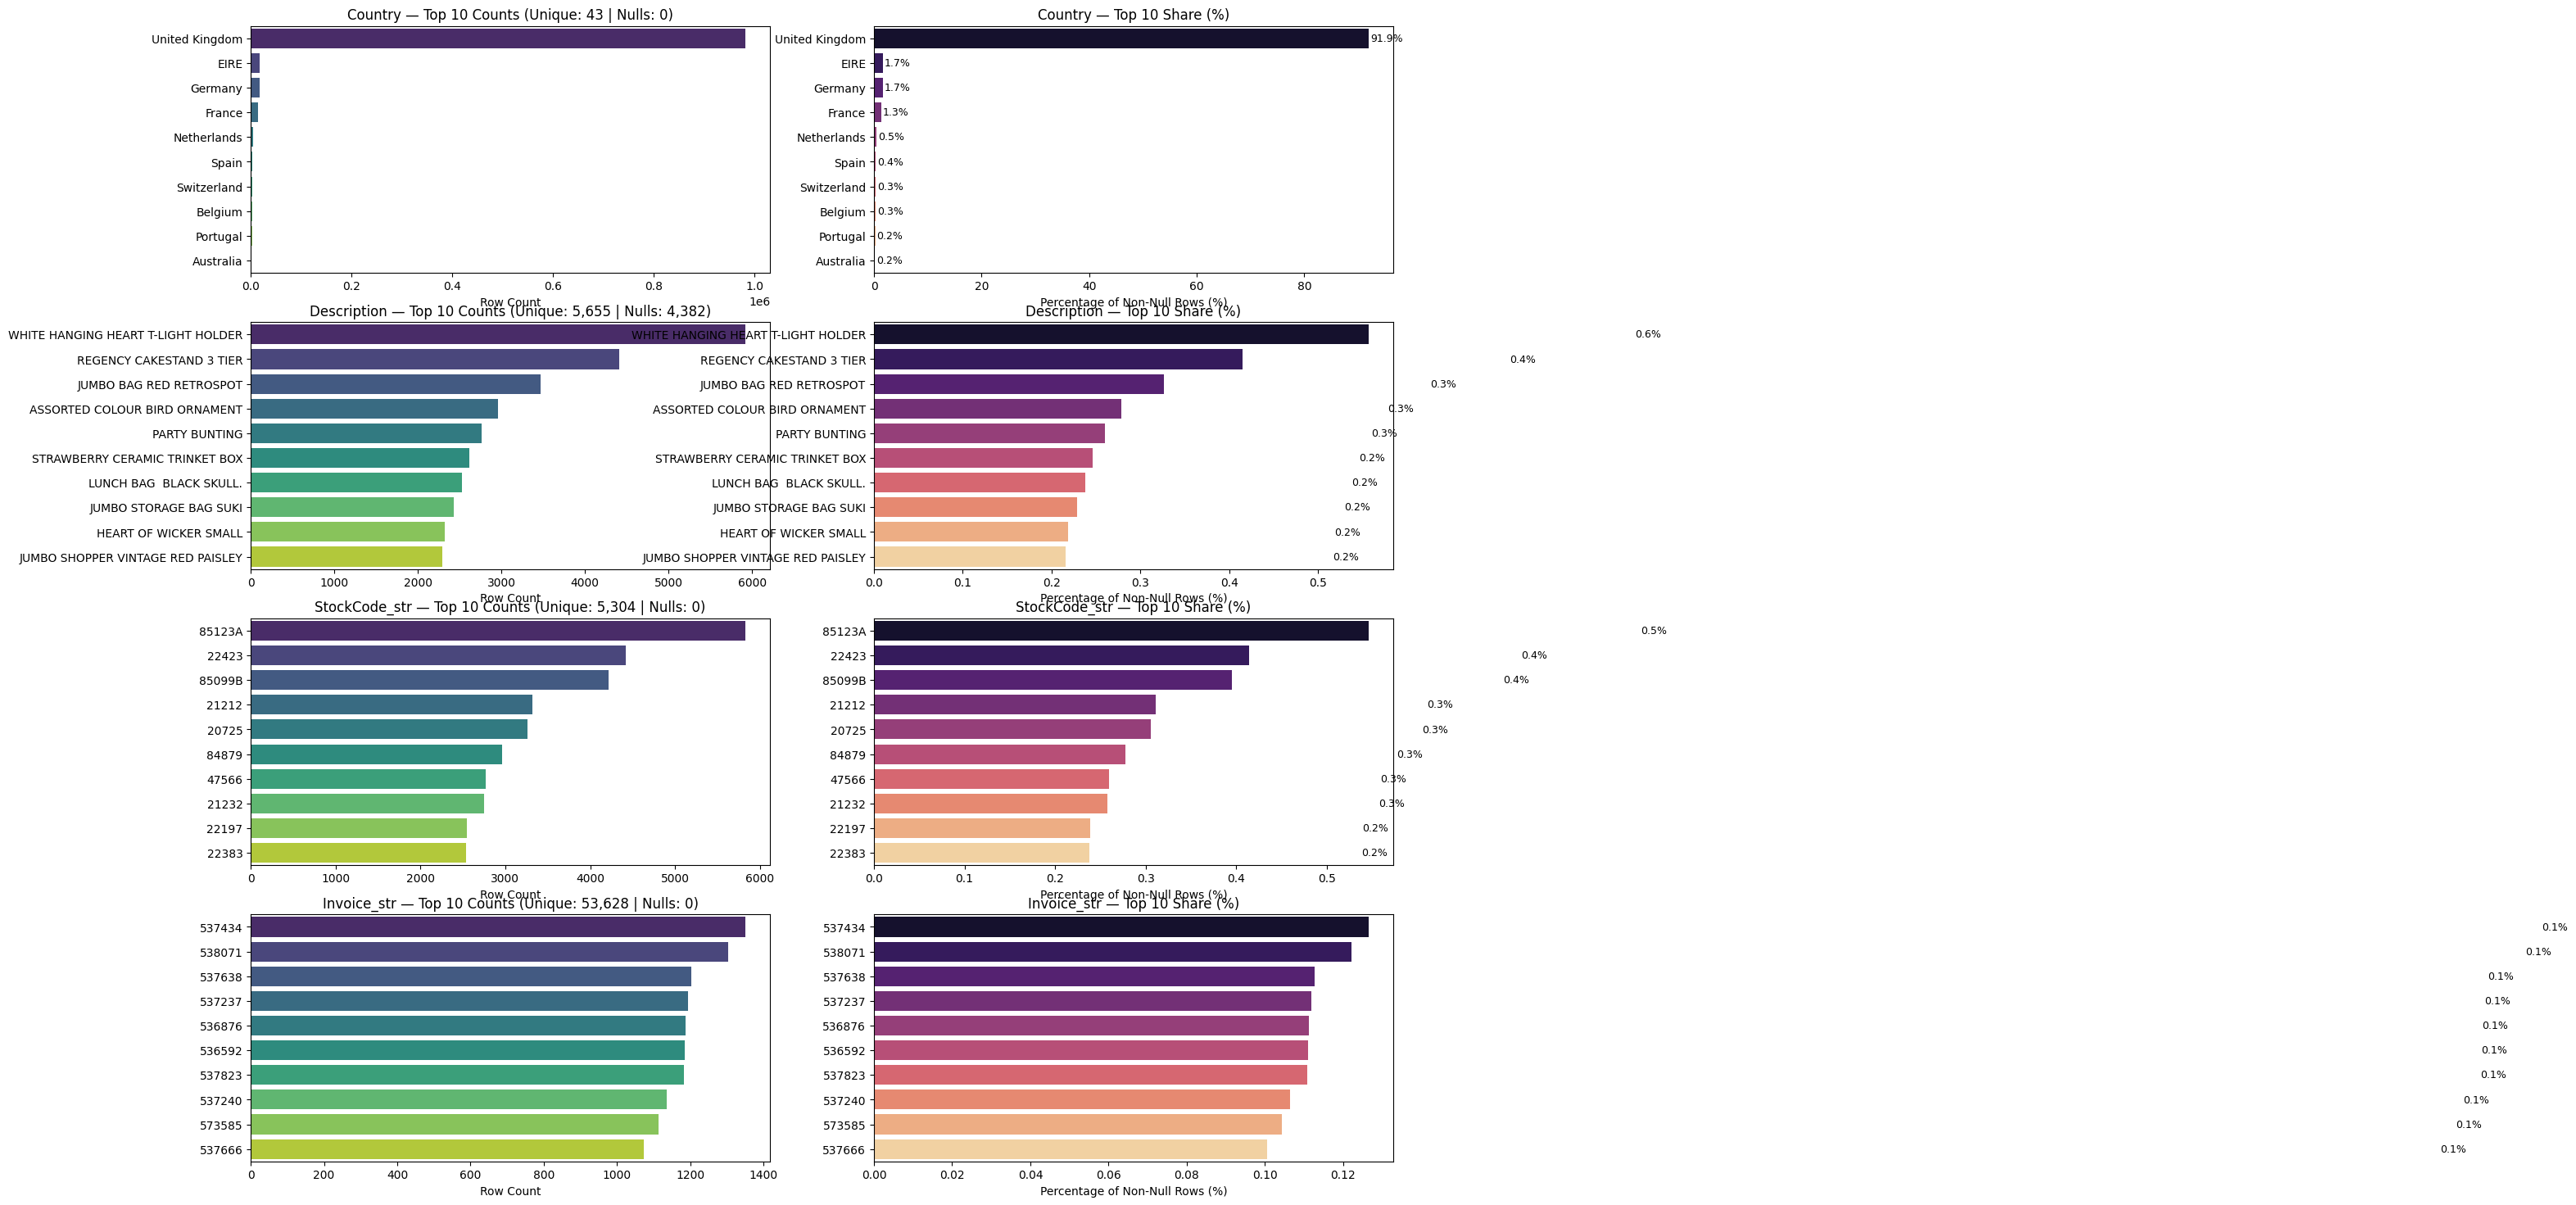

In [ ]:
'''# Plot Top 10 categories for Country, Description, and StockCode
obj_cols_to_plot = ['Country', 'Description', 'StockCode_str', 'Invoice_str']
plot_categorical_diagnostics(df, obj_cols_to_plot, top_n=10)
'''

C:\Users\pushk\AppData\Local\Temp\ipykernel_33448\1041756524.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_counts.values, y=short_labels, ax=axes[idx][0], palette='viridis')
C:\Users\pushk\AppData\Local\Temp\ipykernel_33448\1041756524.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_pct.values, y=short_labels, ax=axes[idx][1], palette='magma')
C:\Users\pushk\AppData\Local\Temp\ipykernel_33448\1041756524.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_counts.values, y=short_labels, ax=axes[idx][0], palette='v

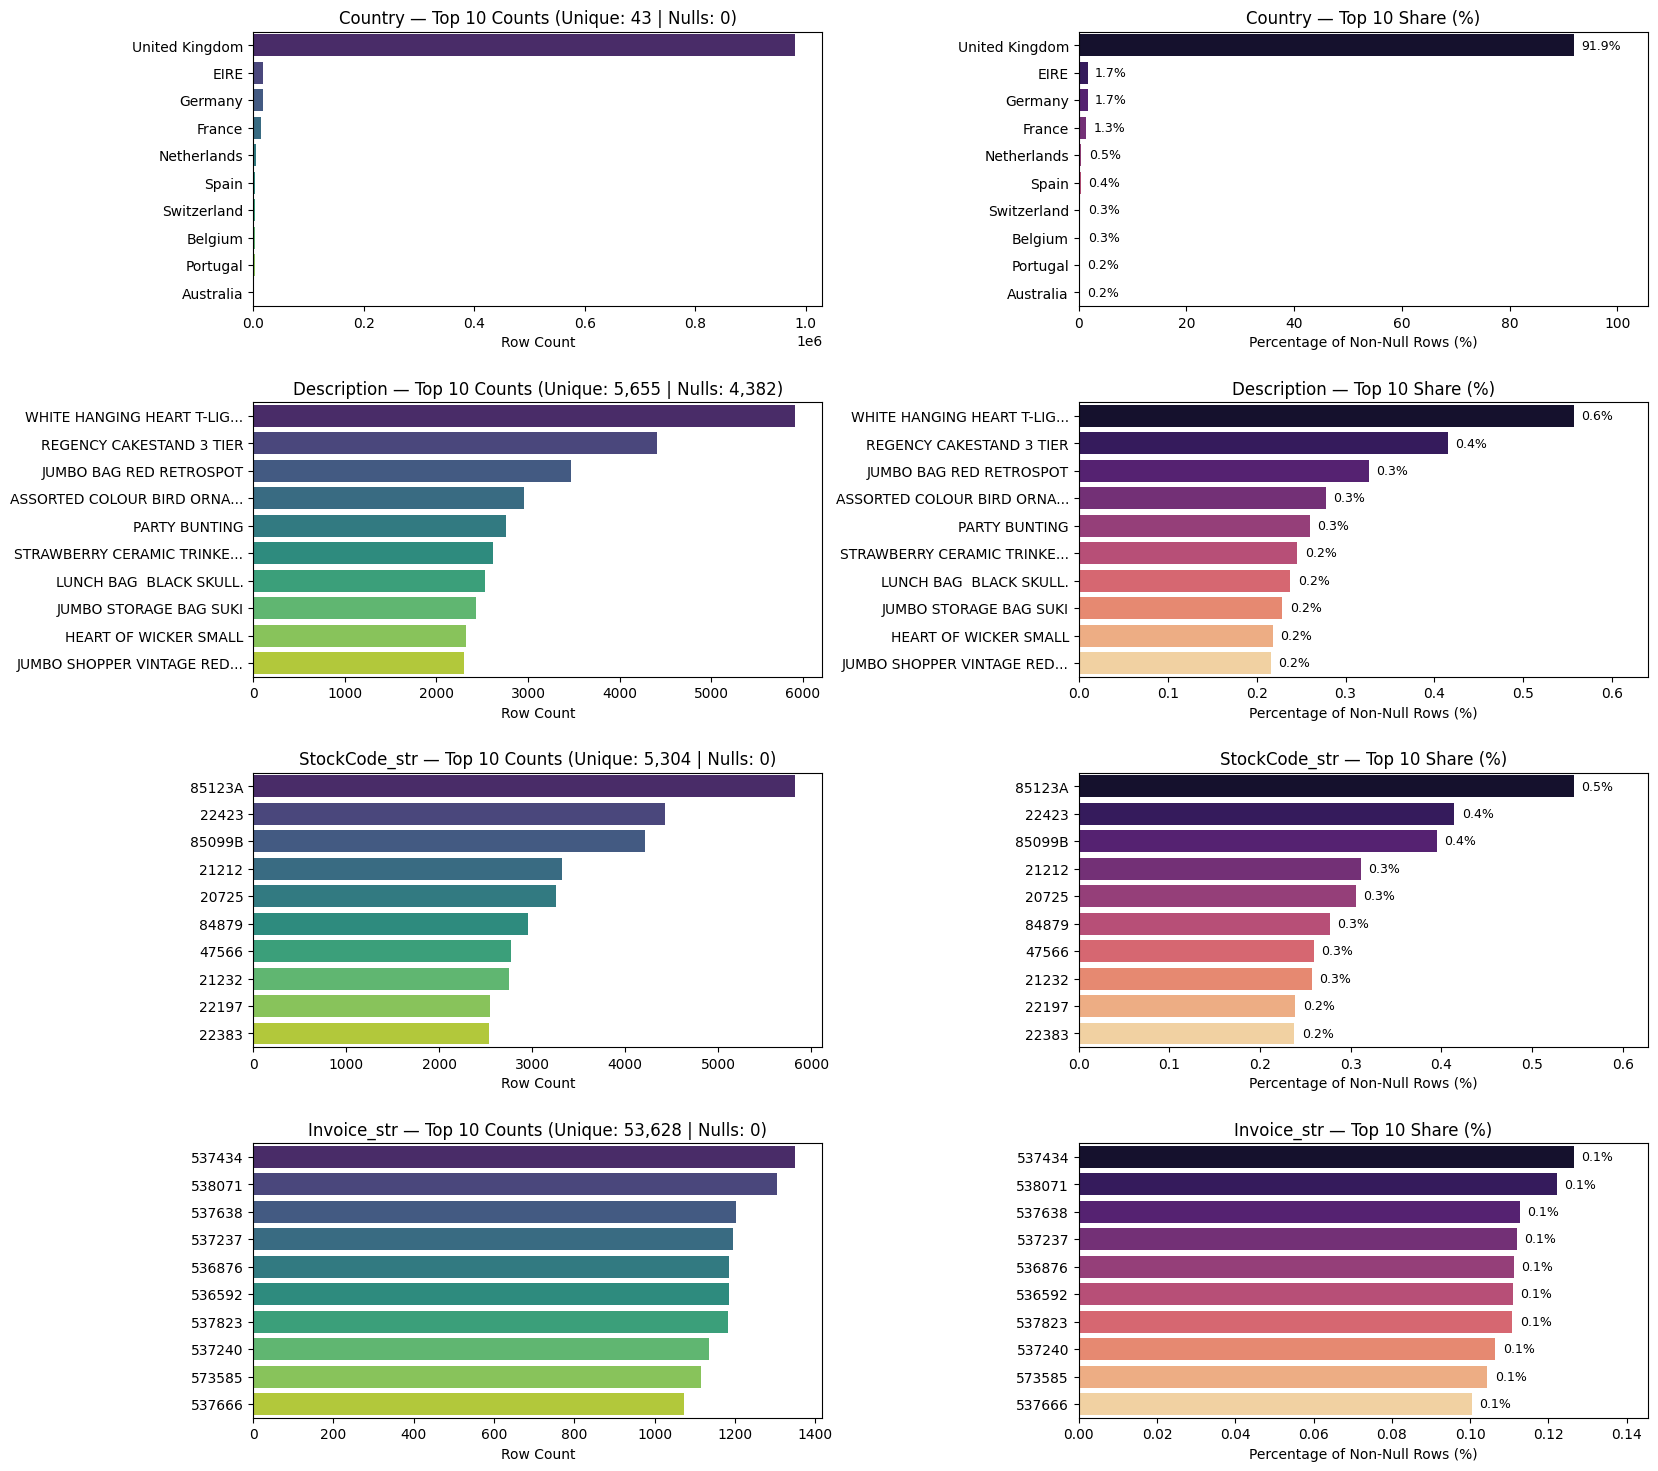

In [88]:
def plot_categorical_diagnostics(df, cols, top_n=10, max_label_len=25):
    """
    Plots Top N category frequencies and percentage shares side-by-side 
    with dynamic label spacing so text never overflows or overlaps.
    """
    n_rows = len(cols)
    fig, axes = plt.subplots(n_rows, 2, figsize=(18, 4.5 * n_rows))
    if n_rows == 1:
        axes = [axes]

    for idx, col in enumerate(cols):
        series = df[col].dropna().astype(str).str.strip()
        n_unique = series.nunique()
        missing_count = df[col].isnull().sum()
        
        top_counts = series.value_counts().head(top_n)
        top_pct = (top_counts / len(series)) * 100

        # Truncate very long product names so they don't collide with the left plot
        short_labels = [
            lbl[:max_label_len] + '...' if len(lbl) > max_label_len else lbl
            for lbl in top_counts.index
        ]

        # Left Plot: Raw Row Counts
        sns.barplot(x=top_counts.values, y=short_labels, ax=axes[idx][0], palette='viridis')
        axes[idx][0].set_title(f"{col} — Top {min(top_n, n_unique)} Counts (Unique: {n_unique:,} | Nulls: {missing_count:,})")
        axes[idx][0].set_xlabel("Row Count")
        axes[idx][0].set_ylabel("")

        # Right Plot: Percentage Share (%)
        sns.barplot(x=top_pct.values, y=short_labels, ax=axes[idx][1], palette='magma')
        axes[idx][1].set_title(f"{col} — Top {min(top_n, n_unique)} Share (%)")
        axes[idx][1].set_xlabel("Percentage of Non-Null Rows (%)")
        axes[idx][1].set_ylabel("")
        
        # Give 15% extra breathing room on the x-axis for the text labels
        max_x = top_pct.max()
        axes[idx][1].set_xlim(0, max_x * 1.15)

        # Proportional offset (1.5% of max x-value) keeps text right next to every bar
        for bar, pct in zip(axes[idx][1].patches, top_pct.values):
            axes[idx][1].text(
                bar.get_width() + (max_x * 0.015),
                bar.get_y() + bar.get_height() / 2,
                f"{pct:.1f}%",
                va='center',
                fontsize=9
            )

    plt.subplots_adjust(wspace=0.45, hspace=0.35)
    plt.show()

# Run on Country, Description, and StockCode_str (skip Invoice_str)
plot_categorical_diagnostics(df, ['Country', 'Description', 'StockCode_str', 'Invoice_str'], top_n=10)

C:\Users\pushk\AppData\Local\Temp\ipykernel_33448\1736183910.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=non_uk.values, y=non_uk.index, ax=axes[0], palette='crest')
C:\Users\pushk\AppData\Local\Temp\ipykernel_33448\1736183910.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Normal (0)', 'Cancelled (1)'], y=cancel_counts.values, ax=axes[1], palette='Set2')


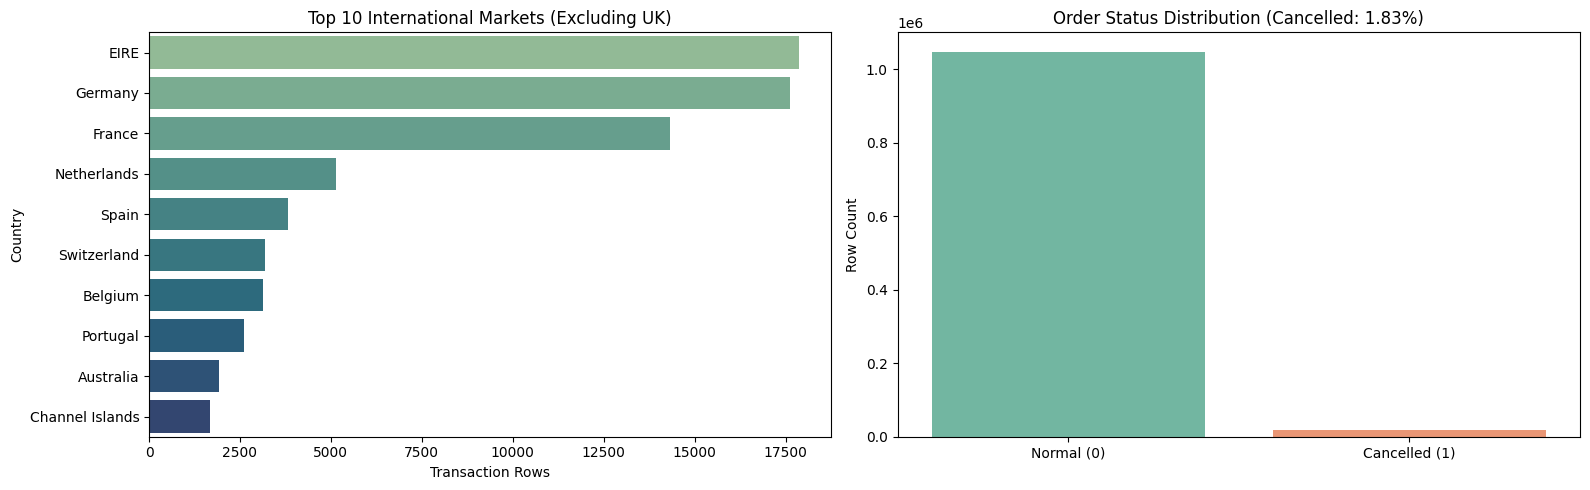

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. International Markets (Excluding UK so smaller bars are visible)
non_uk = df[df['Country'] != 'United Kingdom']['Country'].value_counts().head(10)
sns.barplot(x=non_uk.values, y=non_uk.index, ax=axes[0], palette='crest')
axes[0].set_title("Top 10 International Markets (Excluding UK)")
axes[0].set_xlabel("Transaction Rows")

# 2. Cancellation Ratio (Extracted from Invoice 'C' prefix)
cancel_counts = df['is_cancelled'].value_counts()
sns.barplot(x=['Normal (0)', 'Cancelled (1)'], y=cancel_counts.values, ax=axes[1], palette='Set2')
axes[1].set_title(f"Order Status Distribution (Cancelled: {cancel_counts[1]/len(df)*100:.2f}%)")
axes[1].set_ylabel("Row Count")

plt.tight_layout()
plt.show()

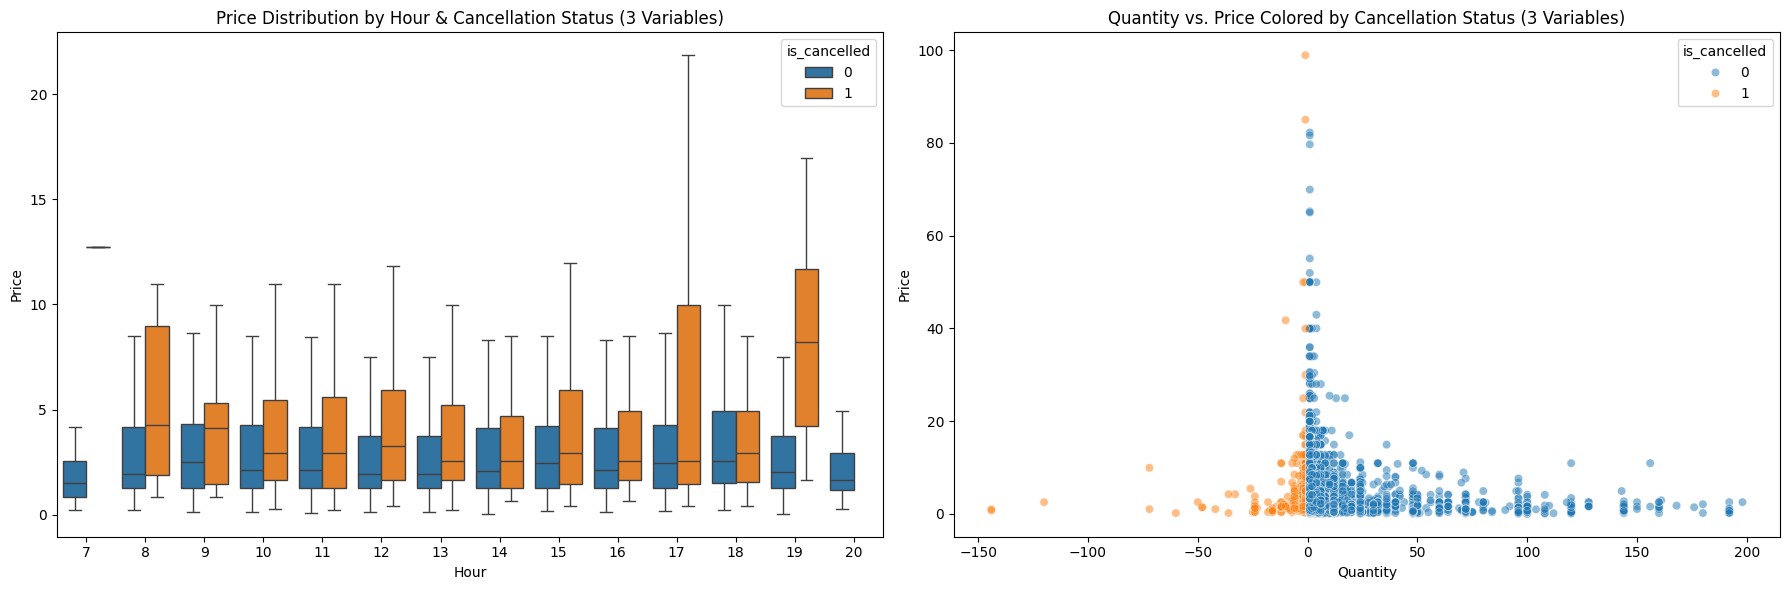

In [90]:
# Sample 20,000 rows so the scatter plot renders fast and cleanly
sample_df = df[(df['Price'] > 0) & (df['Price'] < 100) & (df['Quantity'].abs() < 200)].sample(20000, random_state=42)
sample_df['Hour'] = sample_df['InvoiceDate'].dt.hour

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Multivariate Plot 1: Hour (X) vs Price (Y) split by is_cancelled (Hue)
sns.boxplot(data=sample_df, x='Hour', y='Price', hue='is_cancelled', showfliers=False, ax=axes[0])
axes[0].set_title("Price Distribution by Hour & Cancellation Status (3 Variables)")

# Multivariate Plot 2: Quantity (X) vs Price (Y) colored by is_cancelled (Hue)
sns.scatterplot(data=sample_df, x='Quantity', y='Price', hue='is_cancelled', alpha=0.5, ax=axes[1])
axes[1].set_title("Quantity vs. Price Colored by Cancellation Status (3 Variables)")

plt.tight_layout()
plt.show()

In [92]:
# 1. Clean df (remove non-products, invalid prices, and duplicates)
df = df[df['StockCode_str'].str[0].str.isdigit()].copy()
df = df[df['Price'] > 0]
df = df.drop_duplicates()

# 2. Create the new feature columns directly in df
df['AbsQuantity'] = df['Quantity'].abs()
df['Hour'] = df['InvoiceDate'].dt.hour
df['DayOfWeek'] = df['InvoiceDate'].dt.dayofweek
df['Month'] = df['InvoiceDate'].dt.month

# Verify the new columns are now in df
print(df[['AbsQuantity', 'Price', 'Hour', 'DayOfWeek', 'Month', 'Country', 'is_cancelled']].head())

   AbsQuantity  Price  Hour  DayOfWeek  Month         Country  is_cancelled
0           12   6.95     7          1     12  United Kingdom             0
1           12   6.75     7          1     12  United Kingdom             0
2           12   6.75     7          1     12  United Kingdom             0
3           48   2.10     7          1     12  United Kingdom             0
4           24   1.25     7          1     12  United Kingdom             0


In [98]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
from numpy import arange
from sklearn.preprocessing import OneHotEncoder, RobustScaler, PowerTransformer, QuantileTransformer
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import KBinsDiscretizer
from sklearn import ensemble, preprocessing
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
from numpy import arange
from sklearn.preprocessing import OneHotEncoder, RobustScaler, PowerTransformer, QuantileTransformer
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer
from sklearn import ensemble, preprocessing
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import FunctionTransformer
# Feature Selection
from sklearn.feature_selection import SelectKBest, f_classif, f_regression, chi2, mutual_info_classif
from sklearn.inspection import permutation_importance



# 1. Define X and y directly from df (your exact flow)
X = df[['AbsQuantity', 'Price', 'Hour', 'DayOfWeek', 'Month', 'Country']]
y = df['is_cancelled']

# 2. Separate numeric and categorical column names
categorical_features = ['Country']
numeric_features = [col for col in X.columns if col not in categorical_features]


# 1️ Numeric pipeline     --For Numeric type columns
num_pipe = Pipeline([
    #('imputer', SimpleImputer(strategy='mean')),
    #('imputer', KNNImputer(n_neighbors=3,weights='uniform',metric='nan_euclidean' )), #weight :or 'distance' , metric: 'manhattan' or 'minkowski' also possible
    #('imputer', IterativeImputer(estimator=BayesianRidge(),max_iter=10,random_state=42)),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())  # Handles skewed retail spend & quantities safely
])

cat_pipe_ohe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])


'''
transformer = ColumnTransformer(transformers=[
    ('num', num_pipe, numeric_features),
    ('cat', cat_pipe_ohe, ['Country'])
], remainder='drop')

'''


transformer = ColumnTransformer(transformers=[
    ('num', num_pipe, numeric_features),
    ('cat', cat_pipe_ohe, categorical_features)
], remainder='drop')



# 5️ Final pipeline
pipeline = Pipeline([
    ('transformer', transformer),
    #('scaler', preprocessing.RobustScaler()), # scaling robust to outliers, #RobustScaler(), minmaxscalar(), PowerTransformer(), QuantileTransformer()
	('select', SelectKBest(score_func=f_classif, k=10)),   #chi2:chisquare is only apply on non negative data, f_classif, mutual_info_classif
    #('imputer', KNNImputer(missing_values=int, n_neighbors=5, weights=['uniform', 'distance'], metric=['nan_euclidean', 'manhattan', 'minkowski'])),
    #('select', PCA(whiten=True))

    #('classifier', LogisticRegression(max_iter=500)),
    #('classifier', LogisticRegression()) #0.85
    #('classifier', GaussianNB()) #0.83
    ('classifier', RandomForestClassifier())
    #('classifier', ensemble.GradientBoostingClassifier())
    #('regressor', LinearRegression())   #47.6
    #('regressor', ensemble.RandomForestRegressor()) #76.2
    #('regressor', SVR())   
    #('random_forest', RandomForestRegressor())
    #('classifier', KNeighborsClassifier(n_neighbors=1)), #55
    #('regressor', linear_model.RANSACRegressor()),
    #('regressor', LinearRegression())
    
])


scores = cross_val_score(pipeline, X, y, cv=10, n_jobs=-1, scoring='f1_macro')  # f1_macro for imbalanced classes, take different values for cv,n_jobs,abd pipleline with differnet models
print("Classification accuracy values using 10-fold CV:", scores)   # any negative or extreme values?
print("Mean classification accuracy: %.4f" % scores.mean())

Classification accuracy values using 10-fold CV: [0.53320686 0.5484583  0.5259456  0.49662836 0.53877057 0.53706454
 0.53409318 0.53639163 0.54278918 0.53131128]
Mean classification accuracy: 0.5325


In [100]:
import joblib
import os

# Fit on your clean X and y
pipeline.fit(X, y)

# Save the entire preprocessing + model pipeline
os.makedirs("models", exist_ok=True)
joblib.dump(pipeline, "models/cancellation_pipe.joblib")
print("Saved full pipeline successfully!")

Saved full pipeline successfully!
